# 04 Budget: security-related NYSC allocations per corps member, 2018 to 2026 (H5)

H5 is descriptive (`docs/preregistration.md`, section 4): the year-by-year series of security-related NYSC allocations per corps member in constant 2024 naira, and the change from 2018 to 2026. No significance test is applied.

Data: NYSC line items in the federal budget details for each year [S556, S557, S559-S562, S565, S571] [A17]; lines classified as security-related by their descriptions [A18]; National Bureau of Statistics consumer price index, November 2009 = 100 to 2024 and 2024 = 100 from 2025, spliced at the 2024 annual mean [S567, S568] [A16]; corps members per year from the national totals in `data/processed/exposure_by_state.csv` [A10]. Allocations are appropriations, not releases or spending. 2024 is not in the series: the signed 2024 Act is a scan without a text layer, and no other published 2024 document lists the approved NYSC lines [S563, S572] [A17].

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from nysc_safety import budget, figures, paths

figures.style()
TABLES = paths.ROOT / "reports" / "tables"
TABLES.mkdir(parents=True, exist_ok=True)

lines, checks = budget.load_lines()
lines.to_csv(paths.DATA_PROCESSED / "budget_lines.csv", index=False)
checks.to_csv(budget.BUDGET_DIR / "nysc_totals_check.csv", index=False)
checks[["year", "source_id", "recurrent_parsed", "recurrent_printed", "capital_projects_parsed", "capital_printed",
        "recurrent_matches", "projects_match"]]

,year,source_id,recurrent_parsed,recurrent_printed,capital_projects_parsed,capital_printed,recurrent_matches,projects_match
0,2018,S556,104249996015,104249996015,762430000,762430000,True,True
1,2019,S557,116059975139,116059975139,287665000,287665000,True,True
2,2020,S559,156456163738,156456163738,99391125,99391125,True,True
3,2021,S560,163359439146,163359439146,842058456,842058456,True,True
4,2022,S561,177841274373,177841274373,942567538,942567538,True,True
5,2023,S562,179400909497,179400909497,802642638,802642638,True,True
6,2025,S571,428719419567,428719419567,2980609809,2980609809,True,True
7,2026,S565,484330847017,484330847017,2086426866,2086426866,True,True


Every year's parsed lines are checked against the NYSC totals printed in the same document: recurrent lines (personnel and overhead, at the 8-digit level) against TOTAL RECURRENT, and capital projects against TOTAL CAPITAL.

In [2]:
summary_by_year = (
    lines[lines["in_total"]]
    .assign(security_related=lambda f: f["category"] != "")
    .pivot_table(index="year", columns="category", values="amount_naira", aggfunc="sum", fill_value=0)
)
summary_by_year.columns = [c or "not_security_related" for c in summary_by_year.columns]
(summary_by_year / 1e9).round(2)

,not_security_related,camps,insurance,security,transport
year,,,,,
2018,91.88,0.15,0.00,0.86,12.12
2019,101.56,0.11,0.08,0.29,14.32
2020,146.70,0.05,1.03,0.17,8.61
2021,149.60,0.07,1.25,0.56,12.72
2022,164.17,0.07,1.25,0.52,12.78
2023,163.48,0.10,1.25,0.87,14.50
2025,394.09,0.39,1.25,1.17,34.79
2026,445.73,0.33,1.25,1.15,37.95


Nominal NYSC allocations by category, billion naira. The largest security-related line in every year is the corps members' kitting, transport and feeding allowance, classified as transport [A18]:

In [3]:
allowance = lines[lines["description"].str.contains(budget.ALLOWANCE) & lines["in_total"]]
allowance[["year", "code", "description", "amount_naira", "category"]]

,year,code,description,amount_naira,category
31,2018,22021032,"CORPS MEMBERS KITTING, TRANSPORT AND FEEDING A...",11651846453,transport
89,2019,22021032,"CORPS MEMBERS KITTING, TRANSPORT AND FEEDING A...",13844673700,transport
148,2020,22021032,"CORPS MEMBERS KITTING, TRANSPORT AND FEEDING A...",8329278738,transport
198,2021,22021032,"CORPS MEMBERS KITTING, TRANSPORT AND FEEDING A...",12173588725,transport
254,2022,22021032,"CORPS MEMBERS KITTING, TRANSPORT AND FEEDING A...",12173588725,transport
316,2023,22021032,"CORPS MEMBERS KITTING, TRANSPORT AND FEEDING A...",12173588725,transport
377,2025,22021032,"CORPS MEMBERS KITTING, TRANSPORT AND FEEDING A...",29547900000,transport
442,2026,22021032,"CORPS MEMBERS KITTING, TRANSPORT AND FEEDING A...",33024900000,transport


## Deflators and corps members

In [4]:
cpi = pd.read_csv(paths.DATA_INTERIM / "cpi_monthly.csv", dtype={"series": str})
annual = budget.annual_cpi(cpi)
factors = budget.deflators(annual)
members = budget.corps_members(pd.read_csv(paths.DATA_PROCESSED / "exposure_by_state.csv"))
old_series = (annual["series"] == "2009") & (annual["year"] <= budget.BASE_YEAR)
new_series = (annual["series"] == "2024") & (annual["year"] > budget.BASE_YEAR)
used = annual[old_series | new_series].set_index("year")
pd.DataFrame({"cpi_series": used["series"], "cpi_annual_mean": used["index"], "months": used["months"],
              "factor_to_2024": factors, "corps_members": members}).loc[2018:2026].round(4)

,cpi_series,cpi_annual_mean,months,factor_to_2024,corps_members
2018,2009,261.5765,12.0,2.9125,306077.5
2019,2009,291.3869,12.0,2.6145,314862.0
2020,2009,329.9841,12.0,2.3087,323646.5
2021,2009,385.9258,12.0,1.9740,332431.0
2022,2009,458.6620,12.0,1.6610,341215.5
2023,2009,571.7659,12.0,1.3324,350000.0
2024,2009,761.8304,12.0,1.0000,375000.0
2025,2024,123.0066,12.0,0.8130,400000.0
2026,2024,138.2834,8.0,0.7232,400000.0


The 2026 factor uses the eight months published to August 2026 [A16]. Corps members per year are interpolated between published national totals for 2018 to 2022 and for 2024, and held at the 2025 figure for 2026 [A10].

## Security-related allocation per corps member

In [5]:
table = budget.measures_table(lines, factors, members)
table.to_csv(TABLES / "h5_budget_by_year.csv", index=False)
view = table.pivot(index="year", columns="measure", values="real_per_member_2024")[list(budget.MEASURES)]
view.round(0)

measure,full,without_allowance,security_only
year,,,
2018,124917.0,14045.0,8190.0
2019,122826.0,7865.0,2370.0
2020,70294.0,10878.0,1208.0
2021,86677.0,14388.0,3311.0
2022,71153.0,11894.0,2519.0
2023,63660.0,17316.0,3299.0
2025,76444.0,16390.0,2383.0
2026,73551.0,13846.0,2088.0


In [6]:
changes = budget.change(table)
changes.to_csv(TABLES / "h5_change_2018_2026.csv", index=False)
changes.round(1)

,measure,per_member_2018,per_member_2026,change_percent
0,full,124917.0,73550.8,-41.1
1,without_allowance,14044.8,13845.6,-1.4
2,security_only,8190.0,2087.9,-74.5


In [7]:
full = table[table["measure"] == "full"].set_index("year")
full[["nysc_total_nominal", "security_related_nominal", "share_of_nysc_total", "security_related_real_2024", "corps_members",
      "real_per_member_2024"]].round(3)

,nysc_total_nominal,security_related_nominal,share_of_nysc_total,security_related_real_2024,corps_members,real_per_member_2024
year,,,,,,
2018,105012426015,13127847212,0.125,3.823429e+10,306077.5,124917.016
2019,116347640139,14791867421,0.127,3.867330e+10,314862.0,122826.198
2020,156555554863,9854246261,0.063,2.275038e+10,323646.5,70293.924
2021,164201497602,14596513287,0.089,2.881400e+10,332431.0,86676.648
2022,178783841911,14616909476,0.082,2.427846e+10,341215.5,71152.865
2023,180203552135,16722259252,0.093,2.228102e+10,350000.0,63660.045
2025,431700029376,37612253262,0.087,3.057743e+10,400000.0,76443.567
2026,486417273883,40683383262,0.084,2.942030e+10,400000.0,73550.759


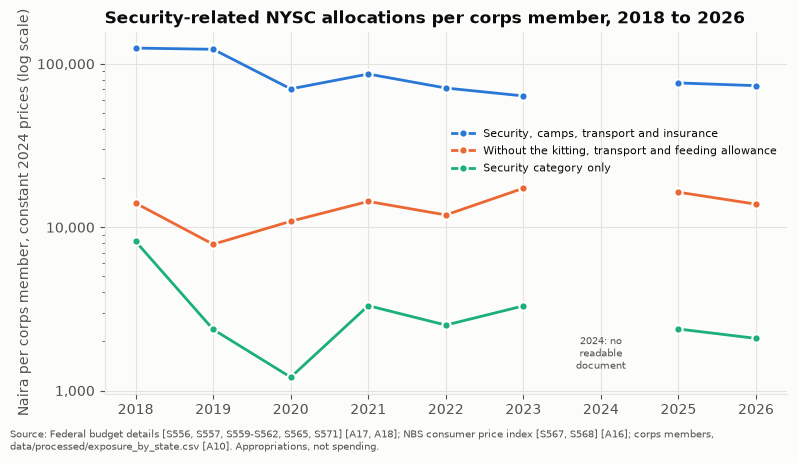

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.6))
labels = {"full": "Security, camps, transport and insurance", "without_allowance": "Without the kitting, transport and feeding allowance",
          "security_only": "Security category only"}
years = range(budget.YEARS[0], budget.YEARS[1] + 1)
plotted = view.reindex(years)
for color, measure in zip(figures.SERIES, budget.MEASURES):
    series = plotted[measure]
    ax.plot(series.index, series.values, color=color, linewidth=2, marker="o", markersize=6,
            markeredgecolor="white", markeredgewidth=1.5, label=labels[measure])
ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.set_ylabel("Naira per corps member, constant 2024 prices (log scale)")
ax.set_xticks(list(years))
ax.text(2024, 1_300, "2024: no\nreadable\ndocument", ha="center", va="bottom", fontsize=7, color=figures.TEXT_SECONDARY)
ax.set_title("Security-related NYSC allocations per corps member, 2018 to 2026", loc="left")
ax.legend(fontsize=8, loc="center right", bbox_to_anchor=(1.0, 0.67))
figures.save(fig, "h5_security_allocation_per_member",
             "Federal budget details [S556, S557, S559-S562, S565, S571] [A17, A18]; NBS consumer price index [S567, S568] [A16]; "
             "corps members, data/processed/exposure_by_state.csv [A10]. Appropriations, not spending.")
plt.show()

### H5 result

Security-related NYSC allocations per corps member fell in real terms between 2018 and 2026 under all three measures. H5, which predicted that they did not rise, holds. The result is descriptive; no test is applied.

Full measure (security, camps, transport and insurance lines [A18]): 124,917 naira per corps member in 2018 and 73,551 naira in 2026, in constant 2024 naira, a fall of 41%. In nominal terms the security-related lines rose from 13.1 billion naira in 2018 to 40.7 billion naira in 2026, but consumer prices rose about 4.0 times over the period (deflator 2.91 for 2018 against 0.72 for 2026) [A16] and the number of corps members by 31% [A10]. The security-related share of the NYSC allocation fell from 12.5% to 8.4%.

The corps members' kitting, transport and feeding allowance accounts for 89% of the full measure in 2018 and 81% in 2026. Per corps member it fell from 110,872 naira in 2018 to 59,705 naira in 2026 in 2024 prices (46% lower).

Without that allowance, security-related lines amounted to 14,045 naira per corps member in 2018 and 13,846 naira in 2026 (1% lower), ranging from 7,865 naira (2019) to 17,316 naira (2023).

Security category alone: 8,190 naira per corps member in 2018 and 2,088 naira in 2026 (75% lower). The 2018 figure includes a security services line of 754 million naira, closed-circuit cameras and 2,000 life jackets; from 2019 the recurrent line is "security charges" (247 million naira in 2019, 1,114 million naira in 2025 and 2026, nominal). Capital spending on security is small in every year: life jackets, cameras, eight watch towers (2023) and solar security lights (2025, 2026).

An insurance premium line appears from 2019. It is 1.25 billion naira in nominal terms in each year from 2021 to 2026, so in real terms per corps member it fell from 7,430 naira in 2021 to 2,262 naira in 2026.

Limits: the figures are appropriations, not releases or spending. 2024 is missing because its signed Act has no text layer [A17]. The 2026 deflator uses eight months of the index [A16]. Corps members per year are interpolated between published totals, and 2026 is held at 400,000; the planned 2026 figure of 418,000 [S161] would lower the 2026 values by about 4%. Lines are classified by keywords in their descriptions [A18], and amendment acts are not used [A17].